# GANisme — 02. Constitution du jeu d'images

**Objectif.** Passer du catalogue analysé dans `01_eda` à un jeu d'images prêt pour l'entraînement :

1. sélection reproductible de ~8 000 peintures (`ganisme.selection`) ;
2. téléchargement par scraping des pages du catalogue, avec manifeste et reprise (`ganisme.download`) ;
3. **visualisation des images et conséquences sur le prétraitement** (question 5 de l'énoncé) ;
4. contrôles : niveaux de gris, quasi-doublons, fuite entraînement/évaluation ;
5. export d'un fichier unique `data/processed/dataset_64_v1.npz` pour l'entraînement (portable sur Colab).

Le téléchargement lui-même est long (plusieurs heures) : il est lancé hors du notebook, en ligne de
commande, et peut être interrompu puis repris sans perte :

```powershell
$env:PYTHONPATH = "src"
python -m ganisme.download --workers 6
```

Ce notebook relit le manifeste produit et **signale explicitement** si le téléchargement est incomplet.

## 0. Configuration

In [1]:
import json
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "ganisme").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from ganisme.download import ARCHIVE_SIZE
from ganisme.images import (average_hash, brightness, confirm_pairs, load_images,
                            near_duplicate_pairs, saturation)
from ganisme.selection import select_paintings

FEATURES_CSV = ROOT / "data" / "processed" / "paintings_metadata.csv"
MANIFEST_CSV = ROOT / "data" / "processed" / "manifest.csv"
IMAGE_DIR = ROOT / "data" / "processed" / f"images_{ARCHIVE_SIZE}"
DATASET_NPZ = ROOT / "data" / "processed" / "dataset_64_v1.npz"
REPORT_DIR = ROOT / "reports" / "dataset"
FIG_DIR = REPORT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_SIZE = 64
SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.titlesize": 13, "axes.labelsize": 11, "axes.grid": True,
    "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, GREY, ORANGE = "#2a6fdb", "#9aa5b1", "#e07b39"


def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    assert path.stat().st_size > 0, path
    return path


def show_grid(paths, titles=None, ncols=8, size=1.9, title=None):
    """Affiche des images en grille, avec une legende courte sous chacune."""
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * (size + 0.35)))
    for ax in np.ravel(axes):
        ax.axis("off")
    for k, path in enumerate(paths):
        ax = np.ravel(axes)[k]
        ax.imshow(plt.imread(path))
        if titles is not None:
            ax.set_title(titles[k], fontsize=8)
    if title:
        fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    return fig

## 1. Sélection du sous-ensemble

Critères issus de l'EDA, implémentés et testés dans `ganisme.selection` :

| Critère | Justification |
| --- | --- |
| Pas de vues de détail | recadrages partiels, quasi-doublons d'une autre œuvre |
| Pas de fresques | photos in situ (murs, voûtes), éclairage et formats hétérogènes |
| Ratio largeur/hauteur dans [0.5, 2] si connu | un recadrage carré d'une frise ou d'un polyptyque ne garde aucune composition |
| Une seule ligne par œuvre (`work_key`) | limite les quasi-doublons et la mémorisation |
| ≤ 30 peintures par artiste | évite qu'un style domine |
| Quotas par genre équilibrés | les genres rares sont pris entièrement, les autres reçoivent la même part |
| Découpage entraînement / évaluation par hachage de `work_key` (90 / 10) | une œuvre est toujours du même côté : pas de fuite |

**Écart assumé par rapport à la proposition de l'EDA.** Celle-ci limitait le religieux à ~25 %. Les
quotas équilibrés vont plus loin (~14 %), avec une seule règle simple au lieu d'un plafond ad hoc :
la diversité des compositions est plus utile au GAN que la fidélité à la distribution du catalogue.

**Taille : 8 000 images.** C'est le milieu de la cible 5 000-10 000. Pour un DCGAN en 64×64, quelques
milliers d'images suffisent à obtenir des résultats exploitables ; au-delà, le temps de téléchargement
(serveur lent, ~0.5 image/s) devient le facteur limitant.

Le manifeste a été créé à partir de cette sélection : on vérifie qu'ils correspondent toujours.

In [2]:
paintings = pd.read_csv(FEATURES_CSV)
selection = select_paintings(paintings)
manifest = pd.read_csv(MANIFEST_CSV)

# Le manifeste doit correspondre exactement a la selection recalculee (meme code, meme graine).
assert manifest["image_id"].tolist() == selection["image_id"].tolist()
assert manifest["URL"].tolist() == selection["URL"].tolist()
print(f"Selection : {len(selection):,} peintures, {selection['AUTHOR'].nunique():,} artistes")
print("Decoupage :", selection["split"].value_counts().to_dict())

Selection : 8,000 peintures, 2,435 artistes
Decoupage : {'train': 7210, 'eval': 790}


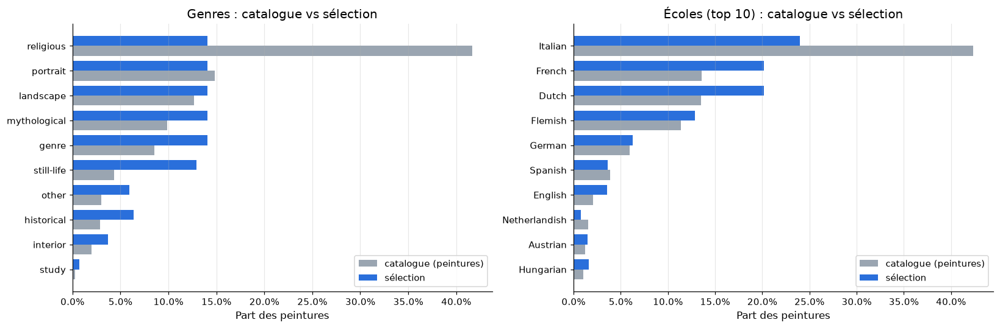

In [3]:
def compare(column, top=None):
    before = paintings[column].value_counts(normalize=True)
    after = selection[column].value_counts(normalize=True)
    table = pd.DataFrame({"catalogue": before, "selection": after}).fillna(0)
    table = table.sort_values("catalogue", ascending=False)
    return table.head(top) if top else table


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, column, title in ((axes[0], "TYPE", "Genres"), (axes[1], "SCHOOL", "Écoles (top 10)")):
    table = compare(column, top=10)
    y = np.arange(len(table))
    ax.barh(y + 0.2, table["catalogue"], height=0.4, color=GREY, label="catalogue (peintures)")
    ax.barh(y - 0.2, table["selection"], height=0.4, color=BLUE, label="sélection")
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(f"{title} : catalogue vs sélection")
    ax.set_xlabel("Part des peintures")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "01_selection_vs_catalogue")
plt.show()

La sélection rééquilibre les genres (le religieux passe de ~42 % à ~14 %) et, par ricochet, les écoles
et les époques (l'école italienne, très liée aux sujets religieux, recule nettement).

## 2. Bilan du téléchargement

Chaque image passe par `pending` → `processed` / `failed` / `skipped`. Les originaux ne sont pas
conservés : chaque image est **recadrée au centre en carré puis réduite en 256×256** (archive, ~20 Ko),
d'où l'on dérive la résolution d'entraînement. Les échecs temporaires sont retentés (3 essais maximum).

In [4]:
status = manifest["status"].value_counts()
display(status.rename("images").to_frame())

done = manifest["status"].isin(["processed", "failed", "skipped"])
COMPLETE = (manifest["status"] == "pending").sum() == 0
if not COMPLETE:
    print(f"ATTENTION : telechargement INCOMPLET ({done.mean():.1%} des images traitees). "
          "Les chiffres et l'export ci-dessous portent sur un jeu PARTIEL.")
else:
    print("Telechargement termine.")

errors = manifest.loc[manifest["status"].isin(["failed", "skipped"]), "error"]
display(errors.str.replace(r"\d+x\d+", "WxH", regex=True).str[:60].value_counts().head(10)
        .rename("occurrences").to_frame())

,images
status,
processed,6779
failed,1141
skipped,80


Telechargement termine.


,occurrences
error,
reseau : The read operation timed out,1135
"ratio reel 0.49 hors [0.5, 2.0]",8
"ratio reel 2.00 hors [0.5, 2.0]",6
"ratio reel 2.03 hors [0.5, 2.0]",5
"ratio reel 0.48 hors [0.5, 2.0]",5
"ratio reel 2.06 hors [0.5, 2.0]",4
"ratio reel 2.04 hors [0.5, 2.0]",4
"ratio reel 0.46 hors [0.5, 2.0]",3
"ratio reel 2.01 hors [0.5, 2.0]",3


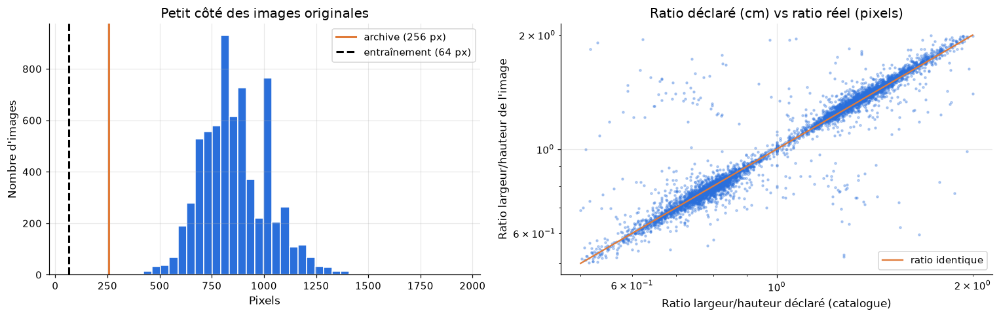

6,779 images traitees ; petit cote median 850 px, min 300 px
Ratio reel a +/-10 % du ratio declare : 94.4% des images avec dimensions


In [5]:
ok = manifest[manifest["status"] == "processed"].copy()
ok["path"] = ok["local_path"].map(lambda p: IMAGE_DIR / Path(p).name)
missing = ~ok["path"].map(Path.exists)
assert not missing.any(), f"{missing.sum()} fichiers annonces comme traites sont absents"

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
short_side = ok[["orig_width", "orig_height"]].min(axis=1)
axes[0].hist(short_side, bins=40, color=BLUE, edgecolor="white")
axes[0].axvline(ARCHIVE_SIZE, color=ORANGE, lw=2, label=f"archive ({ARCHIVE_SIZE} px)")
axes[0].axvline(TRAIN_SIZE, color="black", lw=2, ls="--", label=f"entraînement ({TRAIN_SIZE} px)")
axes[0].set_title("Petit côté des images originales")
axes[0].set_xlabel("Pixels")
axes[0].set_ylabel("Nombre d'images")
axes[0].legend()

real_ratio = ok["orig_width"] / ok["orig_height"]
axes[1].scatter(ok["aspect_ratio"], real_ratio, s=4, alpha=0.3, color=BLUE)
axes[1].plot([0.5, 2], [0.5, 2], color=ORANGE, lw=1.5, label="ratio identique")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Ratio déclaré (cm) vs ratio réel (pixels)")
axes[1].set_xlabel("Ratio largeur/hauteur déclaré (catalogue)")
axes[1].set_ylabel("Ratio largeur/hauteur de l'image")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "02_original_sizes")
plt.show()

print(f"{len(ok):,} images traitees ; petit cote median {short_side.median():.0f} px,"
      f" min {short_side.min():.0f} px")
both = ok["aspect_ratio"].notna()
gap = (np.log(real_ratio[both] / ok.loc[both, "aspect_ratio"])).abs()
print(f"Ratio reel a +/-10 % du ratio declare : {(gap < np.log(1.1)).mean():.1%} des images avec dimensions")

Les images originales font en général largement plus de 256 px de petit côté : l'archive 256×256 ne
perd pas d'information utile pour un entraînement en 64×64 ou 128×128. Le ratio réel des images
correspond le plus souvent au ratio déclaré en cm ; les écarts viennent d'images recadrées par la
source ou photographiées avec leur cadre.

## 3. Visualisation des images

Échantillon aléatoire, puis un échantillon par genre. Les images affichées sont les archives 256×256
(après recadrage carré central).

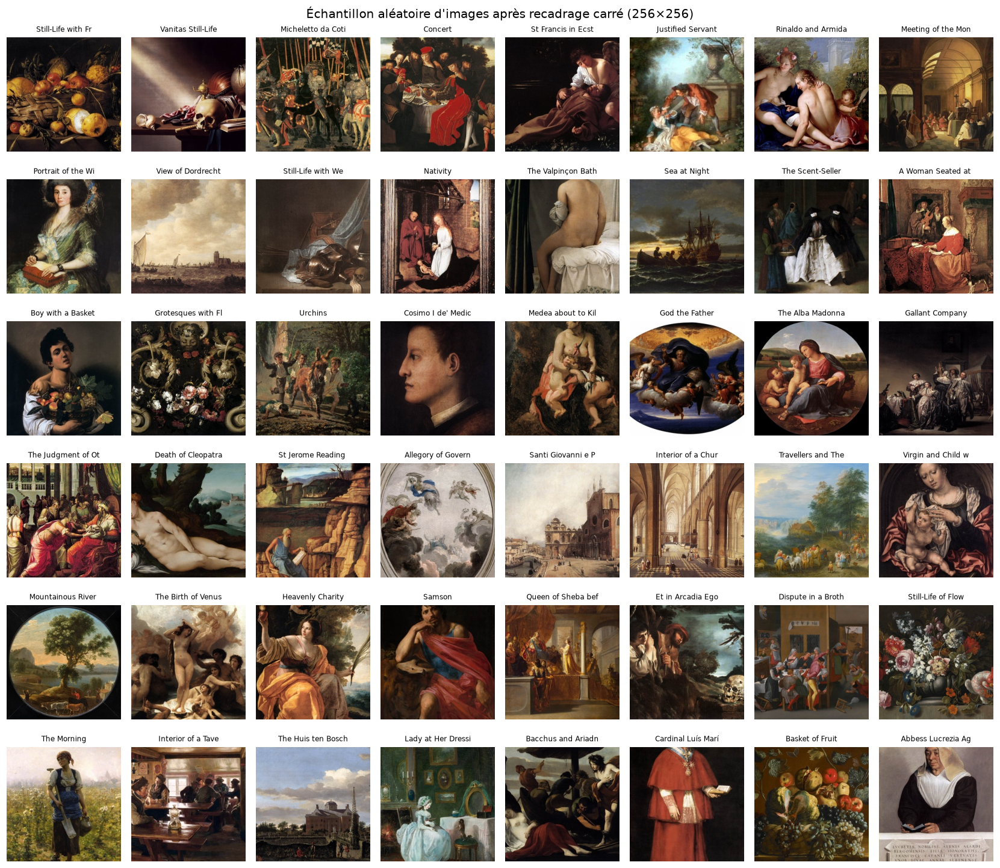

In [6]:
sample = ok.sample(min(48, len(ok)), random_state=SEED)
fig = show_grid(sample["path"].tolist(),
                [f"{t[:18]}" for t in sample["TITLE"]],
                title="Échantillon aléatoire d'images après recadrage carré (256×256)")
save_fig(fig, "03_random_sample")
plt.show()

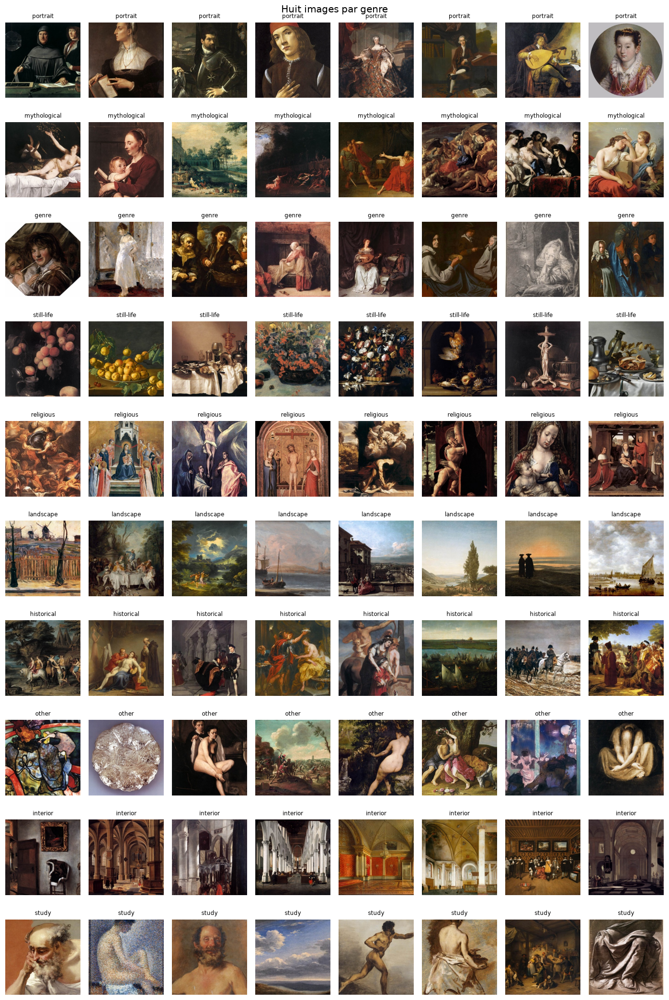

In [7]:
genres = ok["TYPE"].value_counts().index.tolist()
per_genre = 8
paths, titles = [], []
for genre in genres:
    rows = ok[ok["TYPE"] == genre].sample(min(per_genre, (ok["TYPE"] == genre).sum()), random_state=SEED)
    paths += rows["path"].tolist()
    titles += [genre] * len(rows)
fig = show_grid(paths, titles, ncols=per_genre, size=1.6, title="Huit images par genre")
save_fig(fig, "04_by_genre")
plt.show()

### Observations (question 5) et conséquences sur le prétraitement

| Observation | Conséquence |
| --- | --- |
| Formats d'origine variés (portrait, paysage) | recadrage **carré central** : une partie des bords est perdue (~1/4 en médiane, cf. EDA), mais le sujet principal, souvent centré, est conservé |
| Tonalités souvent sombres et brunes (vernis, fonds sombres de natures mortes et portraits) | normaliser les pixels dans **[-1, 1]** (sortie `tanh` du générateur) ; ne **pas** égaliser les couleurs, c'est le style des œuvres |
| Certaines photos montrent le **cadre** ou l'environnement de l'œuvre | bruit pour le GAN ; part trop faible pour justifier un détourage automatique en baseline |
| Possibles reproductions en **noir et blanc** (photos anciennes) | à mesurer (section 4) et à exclure : le GAN apprendrait à produire des images grises |
| Résolution d'origine large (> 256 px en général) | entraînement en **64×64** pour la baseline, 128×128 possible ensuite sans retélécharger |
| Compositions sans orientation gauche/droite privilégiée | **retournement horizontal** aléatoire comme augmentation (pas de retournement vertical : un ciel en bas n'est pas plausible) |

## 4. Contrôles quantitatifs : couleurs, niveaux de gris, quasi-doublons

On charge toutes les images traitées en 64×64 (la résolution d'entraînement).

Tableau d'images : (6779, 64, 64, 3) uint8


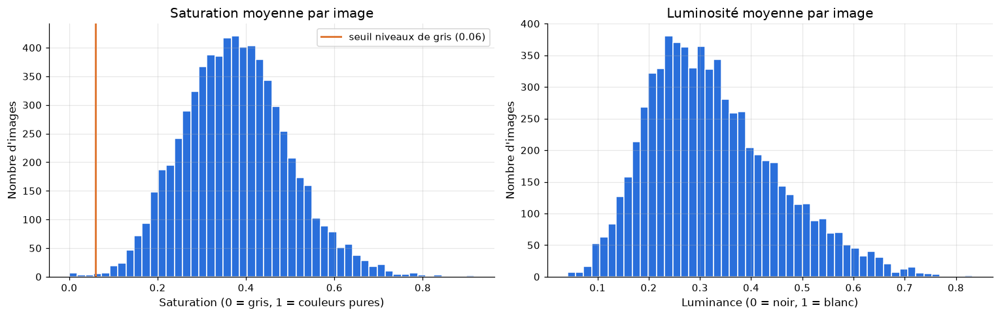

Images quasi en niveaux de gris : 14 (0.2%)
Luminosite mediane : 0.31


In [8]:
images = load_images(ok["path"].tolist(), TRAIN_SIZE)
ok["saturation"] = saturation(images)
ok["brightness"] = brightness(images)
print("Tableau d'images :", images.shape, images.dtype)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(ok["saturation"], bins=50, color=BLUE, edgecolor="white")
GRAY_THRESHOLD = 0.06
axes[0].axvline(GRAY_THRESHOLD, color=ORANGE, lw=2, label=f"seuil niveaux de gris ({GRAY_THRESHOLD})")
axes[0].set_title("Saturation moyenne par image")
axes[0].set_xlabel("Saturation (0 = gris, 1 = couleurs pures)")
axes[0].set_ylabel("Nombre d'images")
axes[0].legend()
axes[1].hist(ok["brightness"], bins=50, color=BLUE, edgecolor="white")
axes[1].set_title("Luminosité moyenne par image")
axes[1].set_xlabel("Luminance (0 = noir, 1 = blanc)")
axes[1].set_ylabel("Nombre d'images")
fig.tight_layout()
save_fig(fig, "05_color_stats")
plt.show()

grayscale = ok["saturation"] < GRAY_THRESHOLD
print(f"Images quasi en niveaux de gris : {grayscale.sum()} ({grayscale.mean():.1%})")
print(f"Luminosite mediane : {ok['brightness'].median():.2f}")

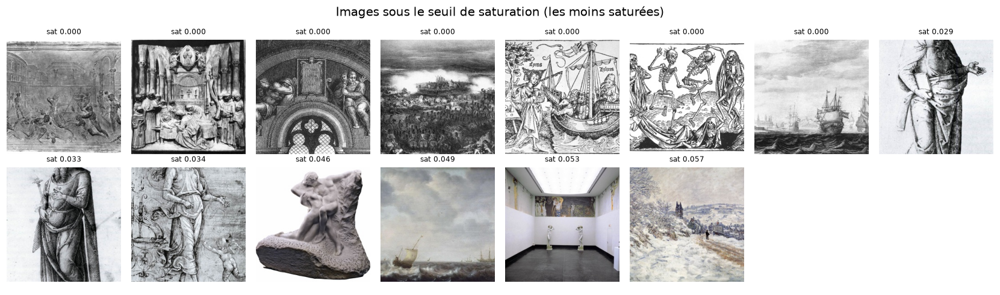

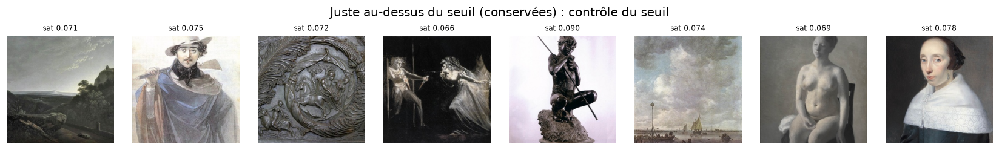

In [9]:
gray_rows = ok[grayscale].sort_values("saturation")
if len(gray_rows):
    fig = show_grid(gray_rows["path"].head(16).tolist(),
                    [f"sat {s:.3f}" for s in gray_rows["saturation"].head(16)],
                    title="Images sous le seuil de saturation (les moins saturées)")
    save_fig(fig, "06_grayscale")
    plt.show()
    border = ok[(ok["saturation"] >= GRAY_THRESHOLD) & (ok["saturation"] < GRAY_THRESHOLD * 1.5)]
    if len(border):
        fig = show_grid(border["path"].head(8).tolist(),
                        [f"sat {s:.3f}" for s in border["saturation"].head(8)],
                        title="Juste au-dessus du seuil (conservées) : contrôle du seuil")
        plt.show()

Le seuil est vérifié visuellement ci-dessus : les images sous le seuil sont celles que l'on exclut,
celles juste au-dessus sont conservées. Le nombre d'images concernées est affiché plus haut ; il se
révèle **faible**, contrairement à ce que laissait craindre l'échantillon de départ.

**Quasi-doublons, en deux temps.**
1. *Candidats* : une empreinte perceptuelle (aHash 8×8) rapproche les images dont la répartition
   clair/sombre est presque identique (distance ≤ 2).
2. *Confirmation* : on garde une paire seulement si l'écart moyen de ses pixels (64×64, de 0 à 255)
   est ≤ 10.

Pourquoi la seconde étape ? L'empreinte seule propose des centaines de paires (plus de 1 600 sur le jeu
complet), presque toutes des **paysages différents** (ciel clair en haut, sol sombre en
bas) : sans confirmation, l'export aurait supprimé des centaines de paysages et biaisé le jeu.

Paires candidates (aHash <= 2) : 1615
Paires confirmees (ecart pixels <= 10) : 3
Dont paires a cheval entre entrainement et evaluation : 0


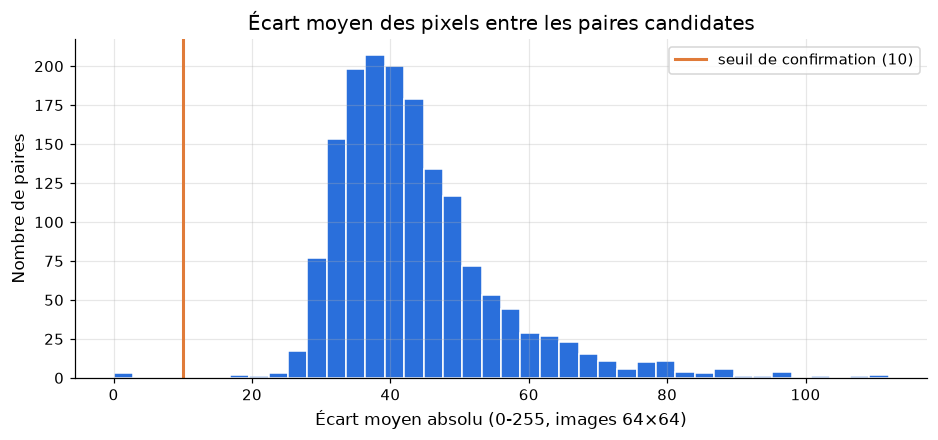

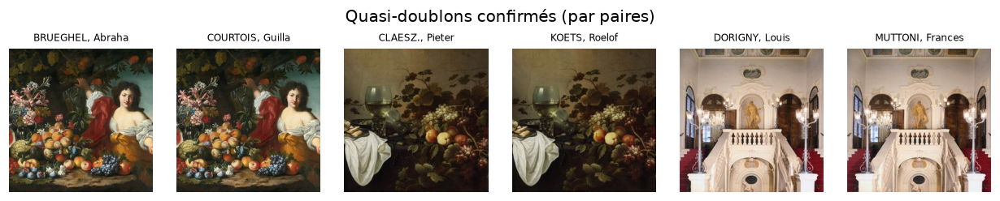

In [10]:
hashes = average_hash(images)
candidates = near_duplicate_pairs(hashes, max_distance=2)
pairs = confirm_pairs(images, candidates, max_mean_diff=10)
diff = np.array([np.abs(images[i].astype(np.int16) - images[j].astype(np.int16)).mean() for i, j in candidates])
print(f"Paires candidates (aHash <= 2) : {len(candidates)}")
print(f"Paires confirmees (ecart pixels <= 10) : {len(pairs)}")

splits = ok["split"].to_numpy()
cross = [(i, j) for i, j in pairs if splits[i] != splits[j]]
print(f"Dont paires a cheval entre entrainement et evaluation : {len(cross)}")

if len(candidates):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(diff, bins=40, color=BLUE, edgecolor="white")
    ax.axvline(10, color=ORANGE, lw=2, label="seuil de confirmation (10)")
    ax.set_title("Écart moyen des pixels entre les paires candidates")
    ax.set_xlabel("Écart moyen absolu (0-255, images 64×64)")
    ax.set_ylabel("Nombre de paires")
    ax.legend()
    save_fig(fig, "07_near_duplicate_check")
    plt.show()

if len(pairs):
    shown = pairs[:6]
    paths = [p for i, j in shown for p in (ok["path"].iloc[i], ok["path"].iloc[j])]
    titles = [f"{ok['AUTHOR'].iloc[k][:16]}" for i, j in shown for k in (i, j)]
    fig = show_grid(paths, titles, ncols=min(12, len(paths)), title="Quasi-doublons confirmés (par paires)")
    plt.show()

In [11]:
# Sauvegarde des controles avant l'export (relus par la presentation).
checks = {
    "processed": int(len(ok)),
    "complete": bool(COMPLETE),
    "status": status.to_dict(),
    "median_short_side_px": float(short_side.median()),
    "share_ratio_within_10pct": round(float((gap < np.log(1.1)).mean()), 4),
    "grayscale": int(grayscale.sum()),
    "median_brightness": round(float(ok["brightness"].median()), 3),
    "near_duplicate_candidates": int(len(candidates)),
    "near_duplicate_confirmed": int(len(pairs)),
}
(REPORT_DIR / "checks.json").write_text(json.dumps(checks, indent=2), encoding="utf-8")
checks

{'processed': 6779,
 'complete': True,
 'status': {'processed': 6779, 'failed': 1141, 'skipped': 80},
 'median_short_side_px': 850.0,
 'share_ratio_within_10pct': 0.9436,
 'grayscale': 14,
 'median_brightness': 0.308,
 'near_duplicate_candidates': 1615,
 'near_duplicate_confirmed': 3}

Le graphique montre l'écart de pixels de chaque paire candidate : les vrais doublons sont à gauche
du seuil, les faux positifs (images différentes) bien au-delà. Pour chaque paire confirmée, on retire
une image : cela supprime le risque de mémorisation et de fuite entre entraînement et évaluation.

## 5. Export du jeu d'entraînement

Règles appliquées :
- images `processed` uniquement ;
- exclusion des images en niveaux de gris ;
- pour chaque paire de quasi-doublons, on retire la seconde image (celle d'évaluation si la paire est
  à cheval, pour ne jamais évaluer sur une image vue à l'entraînement).

In [12]:
drop = set()
for i, j in pairs:
    if i in drop or j in drop:
        continue
    drop.add(j if splits[j] == "eval" or splits[i] == splits[j] else i)

keep = ~grayscale.to_numpy() & ~np.isin(np.arange(len(ok)), list(drop))
final = ok[keep]
final_images = images[keep]

# Controles avant ecriture : pas de fuite, pas d'ensemble vide, valeurs coherentes.
assert set(final.loc[final["split"] == "train", "work_key"]).isdisjoint(final.loc[final["split"] == "eval", "work_key"])
assert final_images.shape[1:] == (TRAIN_SIZE, TRAIN_SIZE, 3) and len(final_images) > 0
assert (final["split"] == "eval").sum() > 0

tmp = DATASET_NPZ.with_name(DATASET_NPZ.stem + ".tmp.npz")
np.savez_compressed(tmp, images=final_images, image_id=final["image_id"].to_numpy(),
                    split=final["split"].to_numpy().astype(str))
# OneDrive peut verrouiller le fichier pendant sa synchronisation : on reessaie quelques fois.
import time
for attempt in range(10):
    try:
        tmp.replace(DATASET_NPZ)
        break
    except PermissionError:
        if attempt == 9:
            raise
        time.sleep(3)

check = np.load(DATASET_NPZ)
assert check["images"].shape == final_images.shape and np.array_equal(check["images"][:10], final_images[:10])
print(f"Export : {DATASET_NPZ.relative_to(ROOT)} ({DATASET_NPZ.stat().st_size / 1e6:.1f} Mo)")
print("Repartition :", pd.Series(check["split"]).value_counts().to_dict())
print(f"Exclues : {int(grayscale.sum())} en niveaux de gris, {len(drop)} quasi-doublons")
if not COMPLETE:
    print("ATTENTION : export PARTIEL, a relancer une fois le telechargement termine.")

mean = final_images.reshape(-1, 3).mean(0) / 255
std = final_images.reshape(-1, 3).std(0) / 255
summary = {
    "complete": bool(COMPLETE),
    "selected": len(selection),
    "status": status.to_dict(),
    "grayscale_excluded": int(grayscale.sum()),
    "near_duplicate_candidates": int(len(candidates)),
    "near_duplicate_pairs": int(len(pairs)),
    "near_duplicates_excluded": len(drop),
    "final": pd.Series(check["split"]).value_counts().to_dict(),
    "train_size": TRAIN_SIZE,
    "rgb_mean": mean.round(4).tolist(),
    "rgb_std": std.round(4).tolist(),
}
(REPORT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
summary

Export : data\processed\dataset_64_v1.npz (72.7 Mo)
Repartition : {'train': 6105, 'eval': 657}
Exclues : 14 en niveaux de gris, 3 quasi-doublons


{'complete': True,
 'selected': 8000,
 'status': {'processed': 6779, 'failed': 1141, 'skipped': 80},
 'grayscale_excluded': 14,
 'near_duplicate_candidates': 1615,
 'near_duplicate_pairs': 3,
 'near_duplicates_excluded': 3,
 'final': {'train': 6105, 'eval': 657},
 'train_size': 64,
 'rgb_mean': [0.377, 0.3118, 0.2547],
 'rgb_std': [0.2555, 0.2351, 0.2139]}

## 6. Conclusion de l'étape

Le jeu `dataset_64_v1.npz` contient les images d'entraînement et d'évaluation en 64×64, en `uint8`, avec
leur `image_id` (lien vers le manifeste et la page source) et leur ensemble (`train` / `eval`). C'est un
fichier unique, facile à copier sur Google Drive pour entraîner sur Colab si aucun GPU local n'est
disponible.

**Prochaine étape :** baseline DCGAN 64×64 (notebook `03_gan`), avec checkpoints complets et grilles
d'images générées à partir de vecteurs latents fixes.